# Peer-to-Peer Lending: Profit Scoring vs Default Scoring on Matured LendingClub Loans, Out-of-Time Portfolio Selection, and Reject Inference with 27 Million Rejected Applications

A lender usually trains its model to predict who defaults. An investor in loans cares about something else: the return after interest, prepayments and recoveries. And every lender learns only from the loans it approved, never from the ones it turned down. This notebook uses the full LendingClub history to test both problems on loans followed to maturity.

**What it does.** It uses the public LendingClub history (2007–2018), the largest U.S. marketplace lender of its time, to answer two questions that matter for any fintech lender or loan investor.

1. **What should a model predict?** A classic **default score**, or the loan's **realised return**, which also reflects the interest rate, early prepayment and recoveries (profit scoring, Serrano-Cinca and Gutiérrez-Nieto, 2016)? Both are trained on loans issued in 2012–2014 and used to pick portfolios from 2015 loans, which are then followed to maturity.
2. **Does it matter that the lender only sees outcomes for approved applications?** The 27 million rejected applications are used to model the approval decision. Rejection is then simulated inside the accepted book to measure the bias, and three **reject-inference** fixes are tested: reweighting, fuzzy augmentation and parcelling.

**Data.** LendingClub accepted and rejected loan files, 2007–2018Q4 (Kaggle `wordsforthewise/lending-club`).

**Methods.** A matured-loan sample, logistic regression, LightGBM and a Keras MLP for default, and LightGBM regression for annualised return, with an out-of-time portfolio back-test. The approval model uses accepted and rejected applications together, with inverse-propensity reweighting, fuzzy augmentation and parcelling.

## 1. Marketplace lending in one page

LendingClub matched borrowers with investors from 2007 until it became a bank in 2020. Applicants were screened (FICO, debt-to-income, employment), approved loans were assigned a **grade** (A–G) and an interest rate, and investors bought fractions of loans. Two features of this model make it a good laboratory:

- **Investors bear the credit risk directly**, so what matters is the return net of defaults, not the default rate alone. A grade-E loan at 20% interest can be a better investment than a grade-A loan at 7% if its losses are below about 13 points.
- **The lender only observes outcomes for approved loans.** A model trained on accepts learns about the population the old policy let in. If it is then used to approve applicants the old policy rejected, its predictions there are extrapolations. This is the **reject-inference** problem (Hand and Henley, 1993; Banasik and Crook, 2007).

**Realised return.** For a matured loan, the annualised return is approximated as
$$R = \Big(\frac{\text{total received}}{\text{funded amount}}\Big)^{1/\tau} - 1,$$
where τ is the time in years until the loan was closed. τ is the term for loans repaid on schedule, the observed life for prepaid loans, and the time to the last payment plus collection time for charged-off loans. This is a simple money-multiple return, not an exact IRR, but it ranks loans correctly in almost all cases.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import lightgbm as lgb
from keras import layers
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 211
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
KAGGLE_DATASET = "wordsforthewise/lending-club"
# 36-month loans: issued 2012–2014 for training, 2015 for the out-of-time test
TRAIN_YEARS, TEST_YEAR = (2012, 2014), 2015
TOP_SHARE = 0.20  # the investor buys the best-ranked 20% of each month's loans
# rejected applications sampled for the approval model
REJECT_SAMPLE = 3_000_000

print(
    f"lightgbm {lgb.__version__} · keras"
    f" {keras.__version__} ({keras.backend.backend()}) · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

…/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


lightgbm 4.7.0 · keras 3.15.1 (torch) · run on 2026-10-21


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Kaggle downloads
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above)
# or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after
# load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """
    Download one file of a Kaggle dataset or competition into data/ (once) and
    return its local path.
    """
    target = DATA_DIR / filename
    if target.exists():
        return target
    # files inside a dataset sub-folder arrive without it
    if (DATA_DIR / Path(filename).name).exists():
        return DATA_DIR / Path(filename).name
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    # large files arrive zipped
    if zipped.exists():
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists() and (DATA_DIR / Path(filename).name).exists():
        return DATA_DIR / Path(filename).name
    if not target.exists():
        raise FileNotFoundError(
            f"{filename} not found after download from {ref}"
        )
    return target

## 3. Matured loans

Only **36-month loans issued 2012–2015** are used. All of them reached maturity (or an earlier final status) before the data were cut at the end of 2018, so every outcome is final. Mixing in loans that are still current would bias the sample towards early defaults and early prepayments. Loan status is kept only if it is "Fully Paid" or "Charged Off".

Features are those known at application: amount, interest rate and grade, FICO band, debt-to-income, income and its verification, employment length, home ownership, purpose, state, credit history length, revolving balance and utilisation, open and total accounts, recent inquiries, delinquencies, public records and mortgages.

In [3]:
USE = [
    "loan_amnt",
    "funded_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "issue_d",
    "loan_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "earliest_cr_line",
    "fico_range_low",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "total_pymnt",
    "recoveries",
    "last_pymnt_d",
    "mort_acc",
    "pub_rec_bankruptcies",
]


def load_accepted():
    parts = []
    # chunks keep memory low
    for ch in pd.read_csv(
        kaggle_file(KAGGLE_DATASET, "accepted_2007_to_2018Q4.csv.gz"),
        usecols=USE,
        chunksize=200_000,
        low_memory=False,
    ):
        ch = ch[
            ch["term"].astype(str).str.contains("36")
            & ch["loan_status"].isin(["Fully Paid", "Charged Off"])
        ].copy()
        ch["issue"] = pd.to_datetime(ch["issue_d"], format="%b-%Y")
        parts.append(
            ch[ch["issue"].dt.year.between(TRAIN_YEARS[0], TEST_YEAR)].drop(
                columns=["term", "issue_d"]
            )
        )
    return pd.concat(parts, ignore_index=True)


L = cached("lendingclub_matured_36m", load_accepted, max_age_hours=24 * 365)
L["y"] = (L["loan_status"] == "Charged Off").astype(int)
L["year"] = L["issue"].dt.year
last = pd.to_datetime(L["last_pymnt_d"], format="%b-%Y", errors="coerce")
months = (
    (last.dt.year - L["issue"].dt.year) * 12
    + (last.dt.month - L["issue"].dt.month)
).clip(lower=1)
# no recorded last payment: charged off at once / ran to term
months = months.fillna(pd.Series(np.where(L["y"] == 1, 1, 36), index=L.index))
# charged-off loans: ~6 months of collections after the last payment
tau = np.where(L["y"] == 1, (months + 6) / 12, np.minimum(months, 36) / 12)
L["ret"] = (L["total_pymnt"] / L["funded_amnt"]).clip(lower=1e-3) ** (
    1 / np.maximum(tau, 1 / 12)
) - 1
L["emp_years"] = (
    L["emp_length"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(float)
    .where(~L["emp_length"].astype(str).str.contains("<"), 0)
)
L["credit_age"] = (
    L["issue"]
    - pd.to_datetime(L["earliest_cr_line"], format="%b-%Y", errors="coerce")
).dt.days / 365.25
L["log_inc"] = np.log1p(L["annual_inc"])
L["inst_to_inc"] = L["loan_amnt"] / L["annual_inc"].replace(0, np.nan)
for c in [
    "grade",
    "sub_grade",
    "home_ownership",
    "verification_status",
    "purpose",
    "addr_state",
]:
    L[c] = L[c].astype("category")
VINT = L.groupby("year").agg(
    loans=("y", "size"),
    default_rate=("y", "mean"),
    mean_rate=("int_rate", "mean"),
    mean_return=("ret", "mean"),
)
print(
    f"{len(L):,} matured 36-month loans 2012–2015 · default rate"
    f" {L['y'].mean():.1%} · mean realised return {L['ret'].mean():.2%}"
)
VINT.round(4)

589,488 matured 36-month loans 2012–2015 · default rate 14.0% · mean realised return 2.59%


,loans,default_rate,mean_rate,mean_return
year,,,,
2012,43470,0.14,12.63,0.02
2013,100422,0.12,13.37,0.04
2014,162570,0.14,12.47,0.03
2015,283026,0.15,11.28,0.02


In [4]:
BYG = L.groupby("grade", observed=True).agg(
    loans=("y", "size"),
    default_rate=("y", "mean"),
    mean_rate=("int_rate", "mean"),
    mean_return=("ret", "mean"),
    sd_return=("ret", "std"),
)
BYG["return / sd"] = BYG["mean_return"] / BYG["sd_return"]
BYG.round(4)

,loans,default_rate,mean_rate,mean_return,sd_return,return / sd
grade,,,,,,
A,133261,0.05,7.21,0.03,0.09,0.31
B,202303,0.11,10.86,0.03,0.14,0.23
C,156060,0.18,13.94,0.02,0.19,0.12
D,72814,0.24,17.26,0.02,0.24,0.06
E,20535,0.29,19.98,0.00,0.27,0.00
F,4052,0.33,23.90,-0.01,0.31,-0.02
G,463,0.40,26.27,-0.05,0.36,-0.15


## 4. Default scoring vs profit scoring

Four models are trained on 2012–2014 loans:
- **logistic regression** for default, on standardised numeric features and one-hot grade, purpose and home ownership;
- **LightGBM classifier** for default, with native categoricals;
- **Keras MLP** for default;
- **LightGBM regressor** for the realised annualised return, the profit score.

The default models do **not** see the interest rate or the grade, so they are a pure credit view. The investor then combines them with the rate to estimate the expected return, $E[R] \approx r\,(1 - \text{PD}) - \text{LGD}\cdot\text{PD}$, with LGD estimated on training charge-offs. The profit model sees everything, including the rate.

LightGBM is early-stopped on 2014 loans held out of its fitting set, with `metric` set explicitly.

In [5]:
NUM = [
    "loan_amnt",
    "emp_years",
    "log_inc",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "mort_acc",
    "pub_rec_bankruptcies",
    "credit_age",
    "inst_to_inc",
]
CATS = ["home_ownership", "verification_status", "purpose", "addr_state"]
tr = L[L["year"].between(*TRAIN_YEARS)]
te = L[L["year"] == TEST_YEAR]
fit_, es_ = tr[tr["year"] < TRAIN_YEARS[1]], tr[tr["year"] == TRAIN_YEARS[1]]
med = tr[NUM].median()
Xn = lambda d: d[NUM].fillna(med)
mu, sd = Xn(tr).mean(), Xn(tr).std()
oh_cols = pd.get_dummies(
    tr[["home_ownership", "purpose", "verification_status"]].astype(str),
    dtype=float,
).columns


def lin_X(d):
    oh = pd.get_dummies(
        d[["home_ownership", "purpose", "verification_status"]].astype(str),
        dtype=float,
    ).reindex(columns=oh_cols, fill_value=0)
    return pd.concat(
        [((Xn(d) - mu) / sd).clip(-6, 6), oh], axis=1
    ).values.astype("float32")


PD = {}
t0 = time.time()
lr = LogisticRegression(C=0.5, max_iter=3000).fit(lin_X(tr), tr["y"])
PD["logistic"] = lr.predict_proba(lin_X(te))[:, 1]
gb = lgb.LGBMClassifier(
    n_estimators=4000,
    learning_rate=0.03,
    num_leaves=63,
    min_child_samples=300,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=5,
    metric="auc",
    verbose=-1,
    random_state=SEED,
)
gb.fit(
    fit_[NUM + CATS],
    fit_["y"],
    eval_set=[(es_[NUM + CATS], es_["y"])],
    callbacks=[lgb.early_stopping(200, verbose=False)],
)
PD["LightGBM"] = gb.predict_proba(te[NUM + CATS])[:, 1]
inp = keras.Input((lin_X(tr[:5]).shape[1],))
h = layers.Dense(128, activation="relu")(inp)
h = layers.Dropout(0.3)(h)
h = layers.Dense(64, activation="relu")(h)
h = layers.Dropout(0.3)(h)
mlp = keras.Model(inp, layers.Dense(1, activation="sigmoid")(h))
mlp.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[keras.metrics.AUC(name="auc")],
)
mlp.fit(
    lin_X(fit_),
    fit_["y"].values,
    validation_data=(lin_X(es_), es_["y"].values),
    epochs=40,
    batch_size=2048,
    verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
        )
    ],
)
PD["neural network"] = mlp.predict(
    lin_X(te), batch_size=8192, verbose=0
).ravel()
pr = lgb.LGBMRegressor(
    n_estimators=4000,
    learning_rate=0.03,
    num_leaves=63,
    min_child_samples=300,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=5,
    metric="l2",
    verbose=-1,
    random_state=SEED,
)
FP = NUM + CATS + ["int_rate", "sub_grade"]
pr.fit(
    fit_[FP],
    fit_["ret"],
    eval_set=[(es_[FP], es_["ret"])],
    callbacks=[lgb.early_stopping(200, verbose=False)],
)
PROFIT = pr.predict(te[FP])
LGD = (
    1
    - (
        tr.loc[tr["y"] == 1, "total_pymnt"]
        / tr.loc[tr["y"] == 1, "funded_amnt"]
    )
    .clip(0, 1)
    .mean()
)
print(
    f"Models in {time.time() - t0:.0f}s · LightGBM default"
    f" {gb.best_iteration_} trees, profit {pr.best_iteration_} trees · LGD on"
    f" training charge-offs {LGD:.1%}"
)
AUC = pd.DataFrame({
    k: {
        "ROC-AUC": roc_auc_score(te["y"], p),
        "PR-AUC": average_precision_score(te["y"], p),
    }
    for k, p in PD.items()
}).T
AUC.loc["LendingClub sub-grade (benchmark)"] = [
    roc_auc_score(te["y"], te["sub_grade"].cat.codes),
    average_precision_score(te["y"], te["sub_grade"].cat.codes),
]
AUC.round(4)

Models in 88s · LightGBM default 243 trees, profit 90 trees · LGD on training charge-offs 36.6%


,ROC-AUC,PR-AUC
logistic,0.66,0.24
LightGBM,0.66,0.24
neural network,0.66,0.24
LendingClub sub-grade (benchmark),0.68,0.25


## 5. Out-of-time portfolio selection (2015 loans)

Every month of 2015, an investor buys the top 20% of that month's loans by each ranking, in equal amounts:
- **highest interest rate**, the naive yield-chaser;
- **best sub-grade** (lowest risk);
- **expected return from each default model**, $r(1-\text{PD}) - \text{LGD}\cdot\text{PD}$;
- **profit model**, the predicted realised return;
- a **random** 20%.

The table reports the realised return of each portfolio, its default rate, and the return per unit of standard deviation across loans.

In [6]:
def pick(score):
    s = pd.Series(score, index=te.index)
    return (
        s.groupby(te["issue"])
        .transform(lambda x: x.rank(ascending=False, pct=True) <= TOP_SHARE)
        .astype(bool)
    )


rate = te["int_rate"].values / 100
SEL = {
    "highest interest rate": te["int_rate"].values,
    "best sub-grade": -te["sub_grade"].cat.codes.values,
    "random": rng.random(len(te)),
}
for k, p in PD.items():
    SEL[f"expected return: {k} PD"] = rate * (1 - p) - LGD * p
SEL["profit model (LightGBM return)"] = PROFIT
PORT = {}
for k, s in SEL.items():
    m = pick(s).values
    r = te.loc[m, "ret"]
    PORT[k] = {
        "loans": int(m.sum()),
        "mean realised return": r.mean(),
        "default rate": te.loc[m, "y"].mean(),
        "mean interest rate": te.loc[m, "int_rate"].mean() / 100,
        "return / sd": r.mean() / r.std(),
        "5th percentile return": r.quantile(0.05),
    }
PORT = pd.DataFrame(PORT).T.sort_values(
    "mean realised return", ascending=False
)
PORT.loc["all 2015 loans"] = [
    len(te),
    te["ret"].mean(),
    te["y"].mean(),
    te["int_rate"].mean() / 100,
    te["ret"].mean() / te["ret"].std(),
    te["ret"].quantile(0.05),
]
IC = {k: spearmanr(s, te["ret"])[0] for k, s in SEL.items()}
PORT["rank IC with realised return"] = pd.Series(IC)
PORT.round(4)

,loans,mean realised return,default rate,mean interest rate,return / sd,5th percentile return,rank IC with realised return
profit model (LightGBM return),"56,599.00",0.03,0.15,0.13,0.19,-0.37,0.11
best sub-grade,"49,710.00",0.03,0.05,0.06,0.33,0.03,-0.45
expected return: neural network PD,"56,599.00",0.03,0.18,0.14,0.12,-0.49,0.26
expected return: LightGBM PD,"56,599.00",0.02,0.18,0.15,0.12,-0.50,0.29
expected return: logistic PD,"56,599.00",0.02,0.19,0.15,0.10,-0.52,0.28
random,"56,599.00",0.02,0.15,0.11,0.10,-0.39,-0.00
highest interest rate,"59,647.00",-0.00,0.27,0.17,-0.02,-0.64,0.45
all 2015 loans,"283,026.00",0.02,0.15,0.11,0.10,-0.39,NaN


## 6. Reject inference

**Step 1: who gets approved?** The rejected-applications file has only a few fields: amount requested, a risk score (FICO-type), debt-to-income, employment length, state and date. An **approval model** (LightGBM) is fitted on accepted versus rejected applications in 2012–2014, on those common fields. Its accuracy shows how mechanical the screening was.

**Step 2: measuring the bias without the rejects' outcomes.** The outcomes of real rejects are unknown, so the bias is measured with a simulation inside the accepted book. A stricter **hypothetical policy** scores every accepted applicant with a simple scorecard on the application fields (FICO, debt-to-income, employment length, amount) and approves the safer applicants with probability $1/(1 + e^{(q - 0.6)/0.08})$, where *q* is the applicant's risk percentile. About 60% are approved, almost all of the safest and almost none of the riskiest, and with some randomness in between, as with real overrides. The others become **pseudo-rejects**, whose outcomes we know but hide from the model. Because the approval probabilities are known, the selection is fully documented, which is what reweighting needs. A default model trained only on pseudo-accepts is then evaluated on the full population and on the pseudo-rejects alone, and compared with:
- **reweighting**: pseudo-accepts are weighted by 1/P(approved), so the weighted sample resembles the full population;
- **fuzzy augmentation**: every pseudo-reject enters twice, as a default with weight PD and as a non-default with weight 1 − PD, using the accepts-only model's PD inflated by a factor *k* = 1.5 (rejected applicants are assumed riskier than the model believes);
- **parcelling**: pseudo-rejects are bucketed by the accepts-only score, and each bucket gets a share of defaults equal to the accepts' default rate there times *k*;
- the **oracle**: the model trained on everybody's real outcomes, which is the upper bound.

In [7]:
def load_rejected():
    parts = []
    for ch in pd.read_csv(
        kaggle_file(KAGGLE_DATASET, "rejected_2007_to_2018Q4.csv.gz"),
        chunksize=1_000_000,
        usecols=[
            "Amount Requested",
            "Application Date",
            "Risk_Score",
            "Debt-To-Income Ratio",
            "State",
            "Employment Length",
        ],
    ):
        ch["date"] = pd.to_datetime(ch["Application Date"], errors="coerce")
        parts.append(ch[ch["date"].dt.year.between(*TRAIN_YEARS)])
    r = pd.concat(parts, ignore_index=True)
    return r.sample(min(REJECT_SAMPLE, len(r)), random_state=SEED).reset_index(
        drop=True
    )


RJ = cached(
    "lendingclub_rejected_sample", load_rejected, max_age_hours=24 * 365
)
common = lambda amt, fico, dti, emp, st: pd.DataFrame({
    "amount": amt.values,
    "fico": fico.values,
    "dti": dti.values,
    "emp": emp.values,
    "state": pd.Categorical(
        st.astype(str).values,
        categories=sorted(L["addr_state"].astype(str).unique()),
    ),
})
rj_emp = (
    RJ["Employment Length"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(float)
    .where(~RJ["Employment Length"].astype(str).str.contains("<"), 0)
)
CA = common(
    tr["loan_amnt"],
    tr["fico_range_low"],
    tr["dti"],
    tr["emp_years"],
    tr["addr_state"],
)
CR = common(
    RJ["Amount Requested"],
    RJ["Risk_Score"],
    pd.to_numeric(
        RJ["Debt-To-Income Ratio"].astype(str).str.rstrip("%"), errors="coerce"
    ),
    rj_emp,
    RJ["State"],
)
APP = pd.concat([CA.assign(a=1), CR.assign(a=0)], ignore_index=True)
APP = APP[APP["fico"].between(300, 850) | APP["fico"].isna()]
va_m = rng.random(len(APP)) < 0.1
appm = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=500,
    metric="auc",
    verbose=-1,
    random_state=SEED,
)
appm.fit(
    APP.loc[~va_m, ["amount", "fico", "dti", "emp", "state"]],
    APP.loc[~va_m, "a"],
    eval_set=[(
        APP.loc[va_m, ["amount", "fico", "dti", "emp", "state"]],
        APP.loc[va_m, "a"],
    )],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
app_auc = roc_auc_score(
    APP.loc[va_m, "a"],
    appm.predict_proba(
        APP.loc[va_m, ["amount", "fico", "dti", "emp", "state"]]
    )[:, 1],
)
print(
    f"Approval model: {(APP['a'] == 1).sum():,} accepted vs"
    f" {(APP['a'] == 0).sum():,} rejected applications (2012–2014) · hold-out"
    f" AUC {app_auc:.3f}"
)
APPROVE = pd.DataFrame({
    "accepted": APP[APP["a"] == 1][["fico", "dti", "amount"]].median(),
    "rejected": APP[APP["a"] == 0][["fico", "dti", "amount"]].median(),
})
APPROVE

Approval model: 306,462 accepted vs 2,941,524 rejected applications (2012–2014) · hold-out AUC 0.996


,accepted,rejected
fico,690.00,643.00
dti,16.72,16.87
amount,"10,000.00","10,000.00"


In [8]:
SCF = ["fico_range_low", "dti", "emp_years", "loan_amnt"]
scx = lambda d: d[SCF].fillna(tr[SCF].median()).values
score = LogisticRegression(max_iter=2000).fit(
    (scx(tr) - scx(tr).mean(0)) / scx(tr).std(0), tr["y"]
)


def p_approve(d):
    pdv = score.predict_proba((scx(d) - scx(tr).mean(0)) / scx(tr).std(0))[
        :, 1
    ]
    q = np.searchsorted(
        np.sort(
            score.predict_proba((scx(tr) - scx(tr).mean(0)) / scx(tr).std(0))[
                :, 1
            ]
        ),
        pdv,
    ) / len(tr)
    return 1 / (1 + np.exp((q - 0.6) / 0.08))


p_app_tr, p_app_te = p_approve(tr), p_approve(te)
# hypothetical stricter policy, about 60% approved
acc = rng.random(len(tr)) < p_app_tr
te_rej = rng.random(len(te)) >= p_app_te
X_tr = tr[NUM + CATS]
y_tr = tr["y"].values
TE_X, TE_y = te[NUM + CATS], te["y"].values
mk = lambda: lgb.LGBMClassifier(
    n_estimators=600,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=300,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    verbose=-1,
    random_state=SEED,
)
RI = {}
base = mk().fit(X_tr[acc], y_tr[acc])
pd_rej = base.predict_proba(X_tr[~acc])[:, 1]
RI["accepts only"] = base
RI["reweighting (1 / P(approved))"] = mk().fit(
    X_tr[acc], y_tr[acc], sample_weight=1 / np.clip(p_app_tr[acc], 0.02, 1)
)
K = 1.5
pf = np.clip(K * pd_rej, 0, 1)
Xf = pd.concat([X_tr[acc], X_tr[~acc], X_tr[~acc]])
yf = np.r_[y_tr[acc], np.ones((~acc).sum()), np.zeros((~acc).sum())]
wf = np.r_[np.ones(acc.sum()), pf, 1 - pf]
RI["fuzzy augmentation (k = 1.5)"] = mk().fit(Xf, yf, sample_weight=wf)
b_acc = pd.qcut(
    base.predict_proba(X_tr[acc])[:, 1],
    10,
    labels=False,
    duplicates="drop",
    retbins=True,
)
edges = b_acc[1]
rate_b = pd.Series(y_tr[acc]).groupby(b_acc[0]).mean().values
b_rej = np.clip(
    np.searchsorted(edges, pd_rej, side="right") - 1, 0, len(rate_b) - 1
)
y_parcel = (
    rng.random((~acc).sum()) < np.clip(K * rate_b[b_rej], 0, 1)
).astype(int)
RI["parcelling (k = 1.5)"] = mk().fit(
    pd.concat([X_tr[acc], X_tr[~acc]]), np.r_[y_tr[acc], y_parcel]
)
RI["oracle (all outcomes known)"] = mk().fit(X_tr, y_tr)
rows = {}
for k, m in RI.items():
    p = m.predict_proba(TE_X)[:, 1]
    rows[k] = {
        "AUC, all 2015 applicants": roc_auc_score(TE_y, p),
        "AUC, pseudo-rejects only": roc_auc_score(TE_y[te_rej], p[te_rej]),
        "mean PD / actual, pseudo-rejects": (
            p[te_rej].mean() / TE_y[te_rej].mean()
        ),
        "mean PD / actual, all": p.mean() / TE_y.mean(),
    }
RIRES = pd.DataFrame(rows).T
print(
    f"Hypothetical policy approves {acc.mean():.0%} of 2012–2014 accepts ·"
    f" 2015 default rate of pseudo-rejects {TE_y[te_rej].mean():.1%} vs"
    f" pseudo-accepts {TE_y[~te_rej].mean():.1%}"
)
RIRES.round(4)

Hypothetical policy approves 60% of 2012–2014 accepts · 2015 default rate of pseudo-rejects 19.5% vs pseudo-accepts 11.2%


,"AUC, all 2015 applicants","AUC, pseudo-rejects only","mean PD / actual, pseudo-rejects","mean PD / actual, all"
accepts only,0.67,0.62,0.89,0.90
reweighting (1 / P(approved)),0.62,0.57,0.71,0.79
fuzzy augmentation (k = 1.5),0.67,0.62,1.27,1.16
parcelling (k = 1.5),0.67,0.62,1.56,1.35
oracle (all outcomes known),0.68,0.63,0.91,0.91


In [9]:
GAIN = pd.DataFrame({
    "default (LightGBM)": pd.Series(
        gb.booster_.feature_importance("gain"), index=NUM + CATS
    ),
    "return (LightGBM)": pd.Series(
        pr.booster_.feature_importance("gain"), index=FP
    ),
})
GAIN = (GAIN / GAIN.sum()).sort_values("return (LightGBM)", ascending=False)
GAIN.head(12).round(3)

,default (LightGBM),return (LightGBM)
addr_state,0.17,0.20
sub_grade,NaN,0.18
log_inc,0.11,0.10
purpose,0.06,0.07
inst_to_inc,0.07,0.07
dti,0.06,0.05
revol_bal,0.06,0.05
int_rate,NaN,0.04
inq_last_6mths,0.05,0.03
loan_amnt,0.04,0.03


## 7. Charts and dashboard

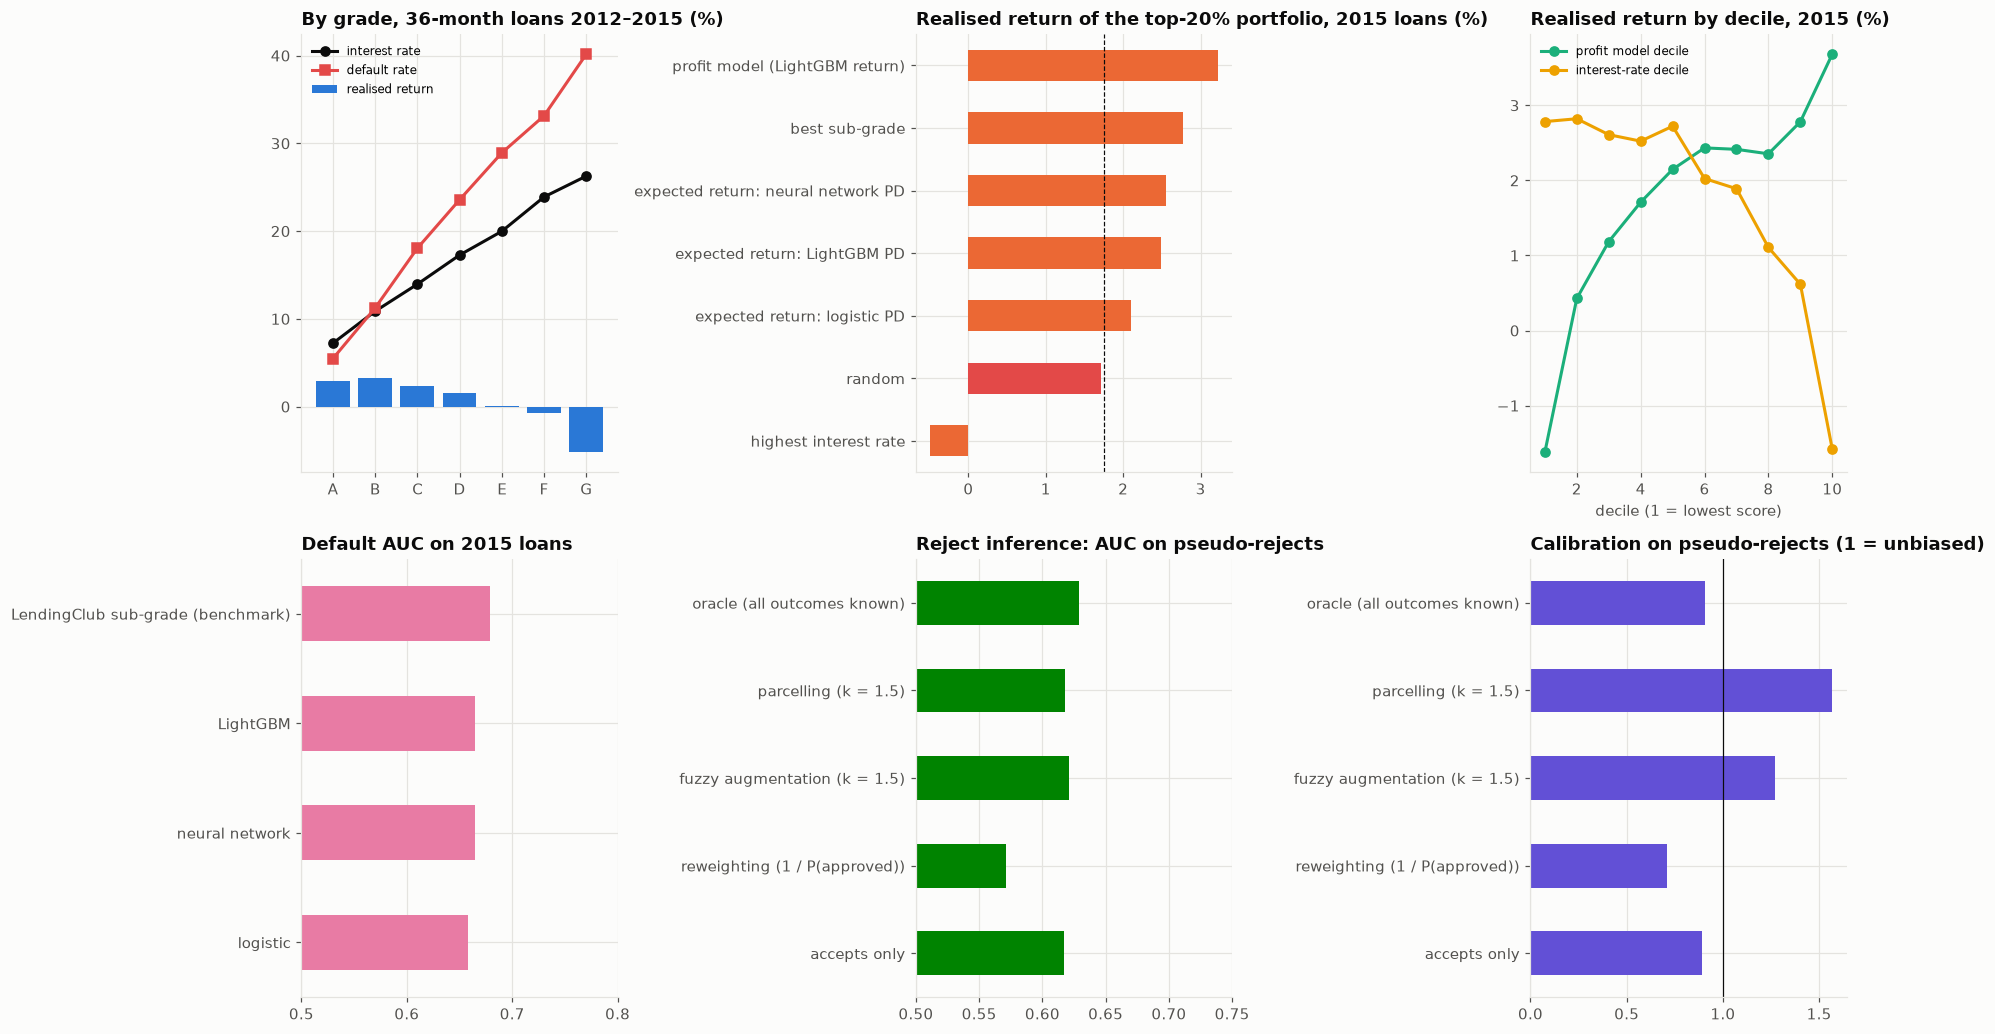

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
a.bar(
    BYG.index.astype(str),
    BYG["mean_return"] * 100,
    color=PALETTE[0],
    label="realised return",
)
a.plot(
    BYG.index.astype(str),
    BYG["mean_rate"],
    marker="o",
    color=INK,
    label="interest rate",
)
a.plot(
    BYG.index.astype(str),
    BYG["default_rate"] * 100,
    marker="s",
    color=STATUS["red"],
    label="default rate",
)
a.set_title("By grade, 36-month loans 2012–2015 (%)")
a.legend(fontsize=8)
a = ax[0, 1]
pp = PORT.drop("all 2015 loans")["mean realised return"].sort_values() * 100
pp.plot.barh(
    ax=a,
    color=[STATUS["red"] if "random" in i else PALETTE[1] for i in pp.index],
)
a.axvline(
    PORT.loc["all 2015 loans", "mean realised return"] * 100,
    color=INK,
    ls="--",
    lw=0.8,
)
a.set_title("Realised return of the top-20% portfolio, 2015 loans (%)")
a = ax[0, 2]
dd = te.assign(p=PROFIT)
q = pd.qcut(dd["p"].rank(method="first"), 10, labels=False)
a.plot(
    range(1, 11),
    dd.groupby(q)["ret"].mean() * 100,
    marker="o",
    color=PALETTE[2],
    label="profit model decile",
)
q2 = pd.qcut(dd["int_rate"].rank(method="first"), 10, labels=False)
a.plot(
    range(1, 11),
    dd.groupby(q2)["ret"].mean() * 100,
    marker="o",
    color=PALETTE[3],
    label="interest-rate decile",
)
a.set_xlabel("decile (1 = lowest score)")
a.set_title("Realised return by decile, 2015 (%)")
a.legend(fontsize=8)
a = ax[1, 0]
AUC["ROC-AUC"].sort_values().plot.barh(ax=a, color=PALETTE[4])
a.set_xlim(0.5, 0.8)
a.set_title("Default AUC on 2015 loans")
a = ax[1, 1]
RIRES[["AUC, pseudo-rejects only"]].plot.barh(
    ax=a, color=PALETTE[5], legend=False
)
a.set_xlim(0.5, 0.75)
a.set_title("Reject inference: AUC on pseudo-rejects")
a = ax[1, 2]
RIRES["mean PD / actual, pseudo-rejects"].plot.barh(ax=a, color=PALETTE[6])
a.axvline(1, color=INK, lw=0.8)
a.set_title("Calibration on pseudo-rejects (1 = unbiased)")
fig.tight_layout()
save_fig(fig, "01_p2p_lending")
plt.show()

In [11]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Top-20% portfolio realised return, 2015 (%)",
        "Realised return by profit-model decile (%)",
        "Reject inference: calibration on pseudo-rejects",
        "By grade: return, rate, default (%)",
    ),
)
dash.add_trace(
    go.Bar(
        x=pp.values,
        y=pp.index,
        orientation="h",
        marker_color=PALETTE[1],
        showlegend=False,
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=list(range(1, 11)),
        y=dd.groupby(q)["ret"].mean() * 100,
        name="profit model",
        line=dict(color=PALETTE[2]),
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=list(range(1, 11)),
        y=dd.groupby(q2)["ret"].mean() * 100,
        name="interest rate",
        line=dict(color=PALETTE[3]),
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=RIRES.index,
        y=RIRES["mean PD / actual, pseudo-rejects"],
        marker_color=PALETTE[6],
        showlegend=False,
    ),
    2,
    1,
)
for c, col in [("mean_return", PALETTE[0]), ("default_rate", STATUS["red"])]:
    dash.add_trace(
        go.Bar(
            x=BYG.index.astype(str), y=BYG[c] * 100, name=c, marker_color=col
        ),
        2,
        2,
    )
dash.add_trace(
    go.Scatter(
        x=BYG.index.astype(str),
        y=BYG["mean_rate"],
        name="interest rate",
        line=dict(color=INK),
    ),
    2,
    2,
)
dash.update_layout(
    height=900,
    width=1400,
    template="simple_white",
    title="Peer-to-peer lending: profit scoring and reject inference",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

**The sample.** 589,488 matured 36-month LendingClub loans issued 2012–2015, with a 14.0% charge-off rate. The mean realised annualised return is 2.6%, falling from 4.0% for 2013 loans to 1.8% for 2015 loans as rates fell and defaults rose. By grade:
- default rates climb from 5% (A) to 40% (G);
- realised returns are 2.4–3.3% for grades A–C, 1.5% for D, about 0% for E and F, and −5% for G;
- returns per unit of risk fall steadily from A (0.31) to G (−0.15).

Investors in high-grade loans were not compensated for the extra risk of low grades.

**Default models barely improve on LendingClub's own grading.** On 2015 loans, logistic regression, LightGBM and a neural network reach a ROC-AUC of 0.66 (PR-AUC 0.24), against 0.68 for the sub-grade, which was assigned with information the public file does not contain. In the default model, the borrower's state (17% of gain) and income (11%) lead.

**Out-of-time portfolio selection (top 20% of each month's 2015 loans).**

| Ranking | Realised return | Default rate | Mean rate | Return / sd |
| --- | --- | --- | --- | --- |
| Profit model (LightGBM on return) | **3.2%** | 14.8% | 12.8% | 0.19 |
| Best sub-grade | 2.8% | 4.5% | 6.5% | **0.33** |
| Expected return from the NN PD | 2.6% | 17.7% | 14.4% | 0.12 |
| Expected return from the LightGBM PD | 2.5% | 18.1% | 14.7% | 0.12 |
| Expected return from the logistic PD | 2.1% | 18.9% | 14.7% | 0.10 |
| Random | 1.7% | 14.9% | 11.3% | 0.10 |
| Highest interest rate | −0.5% | 26.7% | 16.6% | −0.02 |

- **Profit scoring wins on return.** Predicting the realised return directly earns 3.2% against 1.7% for a random selection. Its loans carry about average risk and an above-average rate: it learns which mid-grade loans are underpriced.
- **Chasing yield loses money.** The highest-rate fifth loses 0.5% a year. It is the textbook adverse-selection result for marketplace lending. Its rank correlation with realised returns across *all* loans is still +0.45, because most high-rate loans repay, but the defaults concentrated at the top more than offset the extra yield.
- **The safest loans have the best risk-adjusted return.** The best sub-grades earn 2.8% with a 4.5% default rate and almost no tail (5th-percentile return +2.6%). For a risk-averse investor they dominate.
- Combining a default model with the rate ($r(1-\text{PD}) - \text{LGD}\cdot\text{PD}$, LGD 36.6%) helps (2.1–2.6%), but it overweights high-rate loans because the PD models underestimate their default risk.

**Reject inference.**
- LendingClub's approval is close to mechanical. An approval model on the six fields shared by the accepted and rejected files separates 306,462 accepts from 2.9 million rejects (2012–2014) with an AUC of 0.996. The median risk score is 690 for accepts against 643 for rejects.
- In the simulated stricter policy (60% approved), pseudo-rejects default at 19.5% against 11.2% for pseudo-accepts.

| Method | AUC on pseudo-rejects | Mean PD / actual on pseudo-rejects |
| --- | --- | --- |
| Accepts only | 0.62 | 0.89 |
| Reweighting by 1 / P(approved) | 0.57 | 0.71 |
| Fuzzy augmentation (k = 1.5) | 0.62 | 1.27 |
| Parcelling (k = 1.5) | 0.62 | 1.56 |
| Oracle (all outcomes known) | 0.63 | 0.91 |

**The accepts-only model is nearly as good as the oracle**: 0.62 against 0.63 AUC on the pseudo-rejects, and calibration 0.89 against 0.91. The rejection depends only on variables the model sees (FICO, debt-to-income, employment, amount), so the selection is "missing at random" given the features. Trees and logistic models extrapolate well enough in that case, which is the standard theoretical result (Hand and Henley, 1993).

- **Reweighting makes things worse here.** Approval probabilities as low as 2% give a few risky accepts weights of up to 50, and the resulting high-variance fit loses both ranking and calibration.
- **Augmentation and parcelling only move calibration, in the direction of the assumed k.** They over-predict defaults among rejects by 27% and 56%. Their result is the assumption, which is why regulators treat reject inference as a judgement to document, not a statistical fix.

**Limitations**
- Only 36-month loans issued 2012–2015, all fully observed. 60-month loans and later vintages, which performed worse, are excluded.
- The return is a money-multiple approximation of the IRR, ignoring servicing fees (1% of payments) and the timing of cash flows within the loan's life.
- The pseudo-reject experiment shows what happens when rejection depends on observed data. When it depends on information the lender saw but the model does not (an underwriter's judgement), the accepts-only model would be biased and the outcome of reject inference would hinge even more on the assumed k.

In [12]:
VINT.to_csv(OUT_DIR / "vintages.csv")
BYG.to_csv(OUT_DIR / "by_grade.csv")
AUC.to_csv(OUT_DIR / "default_auc_2015.csv")
PORT.to_csv(OUT_DIR / "portfolio_selection_2015.csv")
RIRES.to_csv(OUT_DIR / "reject_inference.csv")
GAIN.to_csv(OUT_DIR / "feature_gain.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_p2p_lending.png, by_grade.csv, dashboard.html, dashboard.png, default_auc_2015.csv, feature_gain.csv, portfolio_selection_2015.csv, reject_inference.csv, vintages.csv


## References

### Finance and regulation

- Serrano-Cinca, C., & Gutiérrez-Nieto, B. (2016). The use of profit scoring as an alternative to credit scoring systems in peer-to-peer (P2P) lending. *Decision Support Systems, 89*, 113–122. https://doi.org/10.1016/j.dss.2016.06.014
- Hand, D. J., & Henley, W. E. (1993). Can reject inference ever work? *IMA Journal of Management Mathematics, 5*(1), 45–55. https://doi.org/10.1093/imaman/5.1.45
- Banasik, J., & Crook, J. (2007). Reject inference, augmentation, and sample selection. *European Journal of Operational Research, 183*(3), 1582–1594. https://doi.org/10.1016/j.ejor.2006.06.072
- Morse, A. (2015). Peer-to-peer crowdfunding: Information and the potential for disruption in consumer lending. *Annual Review of Financial Economics, 7*, 463–482. https://doi.org/10.1146/annurev-financial-111914-041939
- Emekter, R., Tu, Y., Jirasakuldech, B., & Lu, M. (2015). Evaluating credit risk and loan performance in online peer-to-peer (P2P) lending. *Applied Economics, 47*(1), 54–70. https://doi.org/10.1080/00036846.2014.962222
- Heckman, J. J. (1979). Sample selection bias as a specification error. *Econometrica, 47*(1), 153–161. https://doi.org/10.2307/1912352

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Zadrozny, B. (2004). Learning and evaluating classifiers under sample selection bias. In *Proceedings of the 21st International Conference on Machine Learning*. https://doi.org/10.1145/1015330.1015425
- Shimodaira, H. (2000). Improving predictive inference under covariate shift by weighting the log-likelihood function. *Journal of Statistical Planning and Inference, 90*(2), 227–244. https://doi.org/10.1016/S0378-3758(00)00115-4